# How does a gas disk evolve?
## 1D viscous disk evolution — the Lynden-Bell–Pringle model

In this notebook, we calculate the time evolution of the surface density of a simple axisymmetric disk. The goal is to understand the numerical method: we create a grid, advance the solution in time, make plots, and check how the mass changes.

**Simplifications:** we use dimensionless quantities, constant viscosity, and a thin disk in Keplerian rotation. This is a teaching model, not a full protoplanetary disk simulation. Only `numpy` and `matplotlib` are required.

## The model

The surface density, $\Sigma(r,t)$, follows a diffusion-like equation:

$$\frac{\partial\Sigma}{\partial t}=\frac{3}{r}\frac{\partial}{\partial r}\left[r^{1/2}\frac{\partial}{\partial r}\left(\nu\Sigma r^{1/2}\right)\right].$$

Introduce the coordinate $x=\sqrt{r}$. Then

$$\frac{\partial\Sigma}{\partial t}=\frac{3}{4x^3}\frac{\partial^2}{\partial x^2}(\nu\Sigma x).$$

We approximate the second derivative on the right-hand side with a centred finite difference. At both boundaries, we impose a zero-gradient condition on the surface density, $\partial\Sigma/\partial r=0$, by copying the nearest interior value.

First, let's call 'numpy' and 'matplotlib' to present what's happening...

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 11

## 1. Build the grid

Now, we can move on with the actual implementation.

The first approximation when modeling protoplanetary disks is when the calculation uses a uniform grid in $x=\sqrt{r}$. Fill in the missing lines. As a check, `r` should be an increasing array, and `dx` should be the constant spacing between neighbouring values of `x`.

**Question:** why is the grid uniform in `x` rather than in `r`?

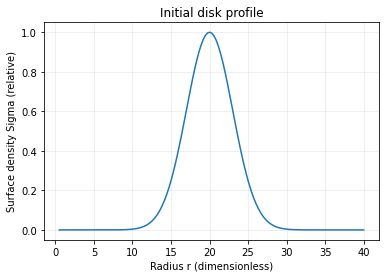

In [2]:
r_inner, r_outer = 0.5, 40.0
n_grid = 180
x = np.linspace(np.sqrt(r_inner), np.sqrt(r_outer), n_grid)
r = x**2
dx = x[1] - x[0]

def initial_profile(r, r_peak=20.0, width=3.0):
    """Return a dimensionless ring-shaped surface-density profile."""
    sigma = np.exp(-0.5 * ((r - r_peak) / width) ** 2)
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    return sigma

sigma0 = initial_profile(r)
plt.plot(r, sigma0)
plt.xlabel("Radius r (dimensionless)")
plt.ylabel("Surface density Sigma (relative)")
plt.title("Initial disk profile")
plt.grid(alpha=0.25)

## 2. Time evolution

The explicit method is stable only when the time step is sufficiently small. The innermost grid point limits the step; the safety factor below keeps $\Delta t$ below the stability limit. If we refine the grid, the allowed time step decreases quadratically.

We estimate the mass in dimensionless units as $M=2\pi\int r\Sigma\,dr$. Material can leave through the boundaries of the finite domain, so the mass does not have to remain constant.

In [3]:
def disk_mass(r, sigma):
    return 2.0 * np.pi * np.trapz(r * sigma, r)

def evolve(sigma_initial, x, nu=1.0, t_end=0.15, safety=0.35, n_snapshots=6):
    """Evolve the disk with an explicit finite-difference scheme."""
    nu_profile = np.asarray(nu, dtype=float)
    if nu_profile.ndim == 0:
        nu_profile = np.full_like(x, float(nu_profile))
    if nu_profile.shape != x.shape or not np.all(np.isfinite(nu_profile)) or np.any(nu_profile <= 0):
        raise ValueError("nu must be positive and finite, either as a scalar or one value per grid point")
    if t_end < 0 or safety <= 0:
        raise ValueError("nu and safety must be positive; t_end cannot be negative")
    dx = x[1] - x[0]
    r = x**2
    sigma = sigma_initial.astype(float).copy()
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    dt_stable = safety * dx**2 * x[0]**2 / (3.0 * np.max(nu_profile))
    save_every = max(1, int(np.ceil(t_end / (dt_stable * max(n_snapshots - 1, 1)))))
    times = [0.0]
    profiles = [sigma.copy()]
    masses = [disk_mass(r, sigma)]
    t = 0.0
    step = 0

    while t < t_end:
        dt = min(dt_stable, t_end - t)
        q = nu_profile * sigma * x
        d2q_dx2 = (q[2:] - 2.0 * q[1:-1] + q[:-2]) / dx**2
        sigma_next = sigma.copy()
        sigma_next[1:-1] += dt * 3.0 * d2q_dx2 / (4.0 * x[1:-1]**3)
        sigma_next[0] = sigma_next[1]
        sigma_next[-1] = sigma_next[-2]
        sigma = sigma_next
        t += dt
        step += 1
        if step % save_every == 0 or t >= t_end:
            times.append(t)
            profiles.append(sigma.copy())
            masses.append(disk_mass(r, sigma))

    return np.array(times), np.array(profiles), np.array(masses), dt_stable

times, profiles, masses, dt_stable = evolve(sigma0, x)
print(f"Stable time step: {dt_stable:.2e}")
print(f"Saved states: {len(times)}; final time: {times[-1]:.3f}")
print(f"Minimum surface density: {profiles.min():.3e}")
assert np.all(np.isfinite(profiles)), "The solution contains non-finite values."
assert profiles.min() > -1e-10, "Negative surface density: reduce the time step."

Stable time step: 5.74e-05
Saved states: 6; final time: 0.150
Minimum surface density: 5.338e-10


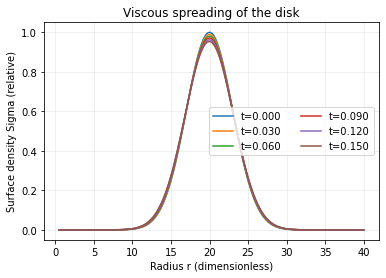

In [4]:
for t, sigma in zip(times, profiles):
    plt.plot(r, sigma, label=f"t={t:.3f}")
plt.xlabel("Radius r (dimensionless)")
plt.ylabel("Surface density Sigma (relative)")
plt.title("Viscous spreading of the disk")
plt.legend(ncol=2)
plt.grid(alpha=0.25)

Initial mass: 944.9766
Final mass:   944.9766


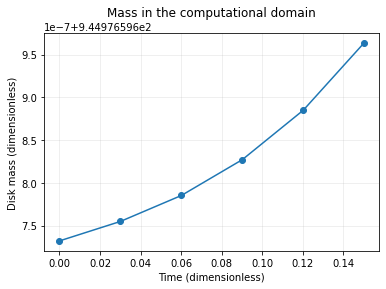

In [5]:
plt.plot(times, masses, marker="o")
plt.xlabel("Time (dimensionless)")
plt.ylabel("Disk mass (dimensionless)")
plt.title("Mass in the computational domain")
plt.grid(alpha=0.25)
print(f"Initial mass: {masses[0]:.4f}")
print(f"Final mass:   {masses[-1]:.4f}")

## 3. Experiment!

Increasing the viscosity speeds up the evolution. Compare the standard run with one using twice the viscosity. Observe how much the disk flattens and spreads over the same dimensionless time.

**Think about:**
1. Why might the calculated mass not remain constant?
2. What would change if we doubled the number of grid points? What would happen to the time step?
3. What physics is missing from this model (for example, temperature-dependent viscosity, dust, or planets)?

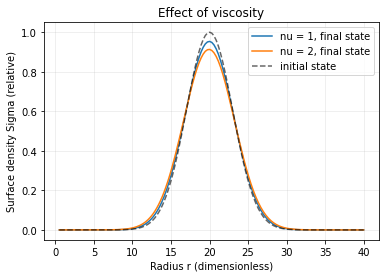

In [6]:
times_fast, profiles_fast, masses_fast, _ = evolve(sigma0, x, nu=2.0)
plt.plot(r, profiles[-1], label="nu = 1, final state")
plt.plot(r, profiles_fast[-1], label="nu = 2, final state")
plt.plot(r, sigma0, "k--", alpha=0.6, label="initial state")
plt.xlabel("Radius r (dimensionless)")
plt.ylabel("Surface density Sigma (relative)")
plt.title("Effect of viscosity")
plt.legend()
plt.grid(alpha=0.25)

## Extension: a power-law disk and a dead zone

Try a power-law surface-density profile, $$\Sigma(r)=\Sigma_0(r/r_0)^{-p},$$ and make the viscosity vary with radius. Here we model a **dead zone** as an annulus with much lower viscosity than the active disk. Smooth edges avoid an abrupt jump in the numerical coefficient. This is a deliberately simple prescription, not a detailed model of ionization or magnetohydrodynamic turbulence.

The solver accepts either a scalar viscosity or an array with one value per grid point. The time-step estimate uses the maximum viscosity. The run below evolves to dimensionless time 0.30 and saves several snapshots. Compare the evolution with the earlier Gaussian-ring example, and plot the viscosity profile to see where the dead zone lies.

Dead-zone run: 6 snapshots through t=0.30; dt = 5.74e-05
Mass: 248.186 -> 245.887


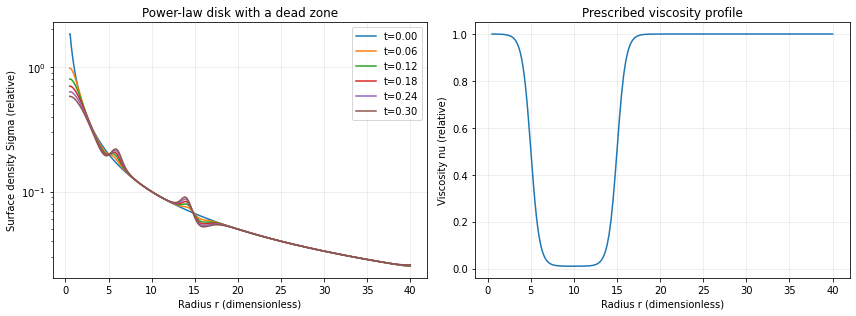

In [ ]:
def power_law_profile(r, sigma0=1.0, r0=1.0, p=1.0):
    """Return Sigma = sigma0 * (r/r0)**(-p), with zero-gradient boundaries."""
    sigma = sigma0 * (r / r0) ** (-p)
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    return sigma

def dead_zone_viscosity(r, nu_active=1.0, r_inner=5.0, r_outer=15.0,
                        reduction=0.01, edge_width=1.0):
    """Return a smooth viscosity profile with a low-viscosity annular dead zone."""
    inner_edge = 0.5 * (1.0 + np.tanh((r - r_inner) / edge_width))
    outer_edge = 0.5 * (1.0 + np.tanh((r_outer - r) / edge_width))
    dead_zone = inner_edge * outer_edge
    return nu_active * (1.0 - (1.0 - reduction) * dead_zone)

sigma_power = power_law_profile(r, sigma0=1.0, r0=1.0, p=1.0)
nu_dead = dead_zone_viscosity(r)
times_dz, profiles_dz, masses_dz, dt_dz = evolve(
    sigma_power, x, nu=nu_dead, t_end=0.30, n_snapshots=6
)
assert np.all(np.isfinite(profiles_dz))
assert profiles_dz.min() > -1e-10

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for t, sigma_t in zip(times_dz, profiles_dz):
    axes[0].plot(r, sigma_t, label=f"t={t:.2f}")
axes[0].set_xlabel("Radius r (dimensionless)")
axes[0].set_ylabel("Surface density Sigma (relative)")
axes[0].set_title("Power-law disk with a dead zone")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[0].set_yscale("log")
axes[1].plot(r, nu_dead)
axes[1].set_xlabel("Radius r (dimensionless)")
axes[1].set_ylabel("Viscosity nu (relative)")
axes[1].set_title("Prescribed viscosity profile")
axes[1].grid(alpha=0.25)
plt.tight_layout()
print(f"Dead-zone run: {len(times_dz)} snapshots through t={times_dz[-1]:.2f}; dt = {dt_dz:.2e}")
print(f"Mass: {masses_dz[0]:.3f} -> {masses_dz[-1]:.3f}")